# Black Friday in the official numbers

Monthly retail trade data from Eurostat, used to check whether November sales jump compared with October, in Greece and across the EU.

**Source:** Eurostat, dataset `sts_trtu_m`, *Turnover and volume of sales in wholesale and retail trade, monthly data*. Downloaded with `scripts/download_eurostat.py`.

| Field | Value | Meaning |
|---|---|---|
| `nace_r2` | `G47` | Retail trade (except motor vehicles) |
| `indic_bt` | `VOL_SLS` | Volume of sales: price changes removed (**main series**) |
| `indic_bt` | `NETTUR` | Net turnover: money taken, includes inflation (only for checks) |
| `unit` | `I21` | Index, average month of 2021 = 100 |
| `s_adj` | `NSA` | Unadjusted |
| `s_adj` | `CA` | Calendar adjusted, **not** seasonally adjusted (**use for Nov/Oct**) |
| `s_adj` | `SCA` | Seasonally and calendar adjusted (removes the November effect, **don't use for Nov/Oct**) |

Greece is `EL` in Eurostat, not `GR`.

## 1. Load the data

In [1]:
from pathlib import Path
import pandas as pd

DATA = Path("../data/raw/sts_trtu_m_G47_2010_2025.csv")
FIG = Path("../figures")          # charts are saved here as PNG
FIG.mkdir(exist_ok=True)

df = pd.read_csv(DATA, parse_dates=["date"])
print(f"{len(df):,} rows, {df['geo'].nunique()} countries/aggregates, "
      f"{df['time'].min()} to {df['time'].max()}")
df.head()

41,942 rows, 41 countries/aggregates, 2010-01 to 2025-12


,geo,geo_name,indic_bt,s_adj,unit,nace_r2,time,date,value,flag
0,AL,Albania,NETTUR,CA,I21,G47,2010-01,2010-01-01,50.9,NaN
1,AL,Albania,NETTUR,CA,I21,G47,2010-02,2010-02-01,49.0,NaN
2,AL,Albania,NETTUR,CA,I21,G47,2010-03,2010-03-01,55.7,NaN
3,AL,Albania,NETTUR,CA,I21,G47,2010-04,2010-04-01,52.4,NaN
4,AL,Albania,NETTUR,CA,I21,G47,2010-05,2010-05-01,57.6,NaN


## 2. What's in it

Which series exist, and for how many countries.

In [2]:
df.groupby(["indic_bt", "s_adj"]).agg(
    countries=("geo", "nunique"),
    first=("time", "min"),
    last=("time", "max"),
    rows=("value", "size"),
)

countries    first     last  rows
indic_bt s_adj                                   
NETTUR   CA            40  2010-01  2025-12  7237
         NSA           37  2010-01  2025-12  6497
         SCA           41  2010-01  2025-12  7249
VOL_SLS  CA            40  2010-01  2025-12  7237
         NSA           36  2010-01  2025-12  6485
         SCA           40  2010-01  2025-12  7237

Quality flags: `p` = provisional, `b` = break in series, `i` = see Eurostat note, blank = normal value.

In [3]:
df["flag"].value_counts(dropna=False)

flag
NaN    36122
p       5558
i        256
b          6
Name: count, dtype: int64

## 3. Keep the EU member states and the EU total

The file also includes euro-area totals and non-EU countries (Norway, Switzerland, Türkiye, Western Balkans). The EU ranking only needs the 27 member states.

In [4]:
EU27 = ["AT", "BE", "BG", "CY", "CZ", "DE", "DK", "EE", "EL", "ES", "FI", "FR", "HR", "HU",
        "IE", "IT", "LT", "LU", "LV", "MT", "NL", "PL", "PT", "RO", "SE", "SI", "SK"]

eu = df[df["geo"].isin(EU27 + ["EU27_2020"])].copy()
missing = sorted(set(EU27) - set(eu["geo"]))
print("Member states missing:", missing or "none")

Member states missing: none


## 4. Wide tables: one column per country

One table per measure, so the series never get mixed up. The variable name says which one it is.

In [5]:
def wide(indic, s_adj):
    """Monthly index values, rows = month, columns = country."""
    sub = eu[(eu["indic_bt"] == indic) & (eu["s_adj"] == s_adj)]
    return sub.pivot(index="date", columns="geo", values="value")

vol_ca  = wide("VOL_SLS", "CA")   # main series for Nov/Oct ratios
vol_nsa = wide("VOL_SLS", "NSA")  # raw, for comparison (no EU total)
vol_sca = wide("VOL_SLS", "SCA")  # seasonally adjusted, NOT for Nov/Oct
tur_nsa = wide("NETTUR", "NSA")   # turnover, only to cross-check ELSTAT

vol_ca.tail()

geo,AT,BE,BG,CY,CZ,DE,DK,EE,EL,ES,...,LU,LV,MT,NL,PL,PT,RO,SE,SI,SK
date,,,,,,,,,,,,,,,,,,,,,
2025-08-01,94.9,88.4,125.5,126.1,97.0,96.5,98.5,92.7,107.6,111.4,...,124.6,112.4,131.4,97.2,111.9,124.3,118.1,98.9,101.0,100.7
2025-09-01,96.3,90.6,123.7,126.1,95.4,96.8,92.3,91.6,98.9,110.5,...,144.5,102.9,122.5,97.0,109.0,115.2,116.6,93.7,99.4,101.9
2025-10-01,98.9,95.0,128.2,126.8,101.7,102.5,96.0,96.8,100.6,111.8,...,149.2,106.5,128.8,102.1,116.7,116.2,114.7,97.6,102.3,107.8
2025-11-01,96.7,92.8,129.4,132.2,114.1,108.2,108.9,93.4,100.1,113.8,...,148.6,105.2,134.2,107.0,111.9,121.1,119.3,105.8,102.0,106.2
2025-12-01,112.5,108.2,142.4,157.9,124.1,113.1,114.8,104.9,110.0,130.9,...,157.1,119.6,145.1,111.7,128.3,139.8,126.9,109.6,112.0,119.0


## 5. First look: Greece, retail volume

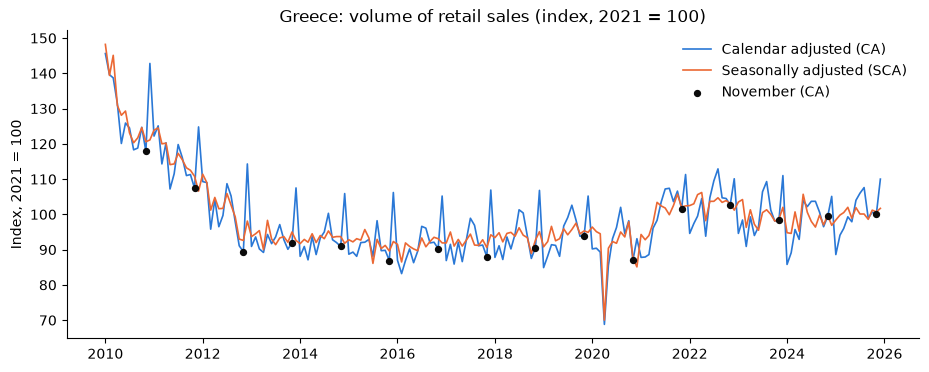

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(vol_ca.index, vol_ca["EL"], label="Calendar adjusted (CA)", lw=1.2, color="#2a78d6")
ax.plot(vol_sca.index, vol_sca["EL"], label="Seasonally adjusted (SCA)", lw=1.2, color="#eb6834")
nov = vol_ca.index.month == 11
ax.scatter(vol_ca.index[nov], vol_ca.loc[nov, "EL"], s=18, zorder=3, color="#0b0b0b", label="November (CA)")
ax.set_title("Greece: volume of retail sales (index, 2021 = 100)")
ax.set_ylabel("Index, 2021 = 100")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG / "01_greece_retail_volume_2010_2025.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 6. Sanity check against ELSTAT

ELSTAT reported Greek retail turnover Nov vs Oct 2024 = **+2.4%**. The 2025 figures have been revised since their first release, so expect small differences there.

In [7]:
def pct(table, geo, a, b):
    return round((table.loc[b, geo] / table.loc[a, geo] - 1) * 100, 1)

print("EL turnover NSA, Nov/Oct 2024:", pct(tur_nsa, "EL", "2024-10-01", "2024-11-01"), "%  (ELSTAT: +2.4%)")
print("EL turnover NSA, Nov/Oct 2025:", pct(tur_nsa, "EL", "2025-10-01", "2025-11-01"), "%  (ELSTAT first release: -1.2%)")

EL turnover NSA, Nov/Oct 2024: 2.4 %  (ELSTAT: +2.4%)
EL turnover NSA, Nov/Oct 2025: -0.6 %  (ELSTAT first release: -1.2%)


In [8]:
df["flag"].value_counts()

flag
p    5558
i     256
b       6
Name: count, dtype: int64

<!-- analysis -->
# Part 3: Greece vs the EU, the whole month

**Measure:** volume of retail sales, calendar adjusted, not seasonally adjusted (`vol_ca`).

**November bump** = % change from October to November in the same year. A positive number means people bought more in November than in October.

**Periods:**
- **2010–2015**: before Black Friday caught on in Greece.
- **2016–2025**: Black Friday era, with 2016 as the marker year. **2020 is left out of averages**: Greece went into lockdown on 7 Nov 2020 and shops closed, so November collapsed for reasons unrelated to Black Friday.

In [9]:
# [analysis] Shared style and helpers
GREECE, EU, MUTED = "#2a78d6", "#eb6834", "#c3c2b7"   # Greece = blue, EU = orange, others = gray
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
})

def nov_bump(table):
    """% change Oct -> Nov for each year, rows = year, columns = country."""
    nov = table[table.index.month == 11]
    oct_ = table[table.index.month == 10]
    out = (nov.to_numpy() / oct_.to_numpy() - 1) * 100
    return pd.DataFrame(out, index=nov.index.year, columns=table.columns).round(1)

bump = nov_bump(vol_ca)
YEARS_BF = [y for y in range(2016, 2026) if y != 2020]   # Black Friday era, without 2020
bump[["EL", "EU27_2020"]].T

date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
geo,,,,,,,,,,,,,,,,
EL,-5.5,-3.5,-1.9,2.1,-1.2,-3.2,-2.0,-3.6,3.5,0.2,-11.4,-4.7,-1.7,0.2,3.0,-0.5
EU27_2020,-3.4,-3.9,-3.2,-1.5,-1.6,-2.4,-2.2,1.3,0.5,0.8,-4.5,1.4,1.9,2.5,2.2,2.5


<!-- bf -->
# Part 2: Black Friday each year in Greece

No official source publishes sales for the Black Friday day or week: Eurostat and ELSTAT only release whole months. So this part combines two things:

1. **Google Trends** searches for "Black Friday" in Greece, which show the day itself. **These are searches, not sales**, and the only non-official source in the project.
2. **November retail sales** (Eurostat, official), as the "Black Friday month" sales.

Google Trends values are relative (0–100). The monthly series is one query, so its years compare directly. The daily series is one query per year, each scaled to its own peak, so only the shape and the peak day compare across years. The Greek term "Μαύρη Παρασκευή" has almost no searches, so the English term is used. Data from `scripts/download_google_trends.py`.

In [10]:
# [bf] Load Google Trends and compute each year's Black Friday date
import datetime as dt

gt_m = pd.read_csv("../data/raw/google_trends_GR_monthly_2010_2025.csv", parse_dates=["date"])
gt_d = pd.read_csv("../data/raw/google_trends_GR_daily_oct_dec_2016_2025.csv", parse_dates=["date"])
print("Google Trends downloaded on:", gt_m["downloaded"].iloc[0])

def black_friday(year):
    """Day after the 4th Thursday of November."""
    d = dt.date(year, 11, 1)
    first_thu = d + dt.timedelta((3 - d.weekday()) % 7)
    return pd.Timestamp(first_thu + dt.timedelta(days=22))

nov_rows = gt_m[gt_m["date"].dt.month == 11]
searches_nov = nov_rows.set_index(nov_rows["date"].dt.year)["Black Friday"]
searches_nov.index.name = "year"

Google Trends downloaded on: 2026-11-25


## 7. Did searches peak on Black Friday itself?

For each year, the day with the most "Black Friday" searches, compared with the actual Black Friday date.

In [11]:
# [bf]
peaks = gt_d.loc[gt_d.groupby("year")["Black Friday"].idxmax(), ["year", "date"]].set_index("year")
peaks.columns = ["peak search day"]
peaks["Black Friday"] = [black_friday(y) for y in peaks.index]
peaks["same day?"] = peaks["peak search day"] == peaks["Black Friday"]
peaks

,peak search day,Black Friday,same day?
year,,,
2016,2016-11-25,2016-11-25,True
2017,2017-11-24,2017-11-24,True
2018,2018-11-23,2018-11-23,True
2019,2019-11-29,2019-11-29,True
2020,2020-11-27,2020-11-27,True
2021,2021-11-26,2021-11-26,True
2022,2022-11-25,2022-11-25,True
2023,2023-11-24,2023-11-24,True
2024,2024-11-29,2024-11-29,True


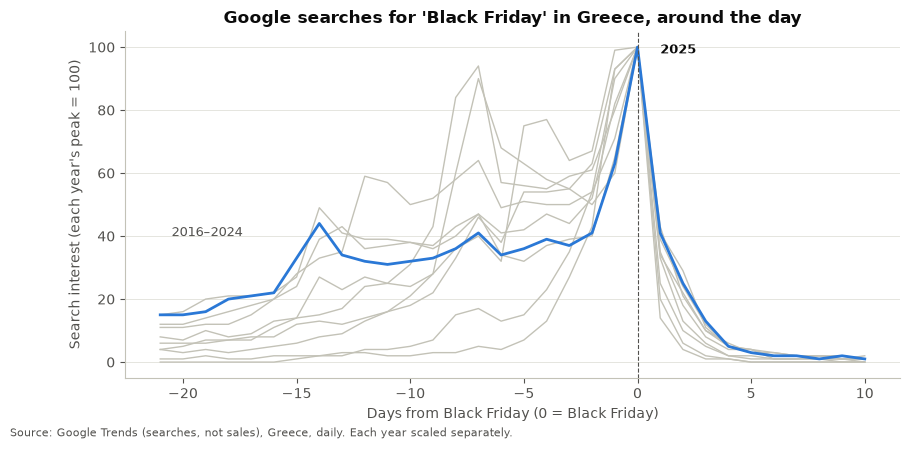

In [12]:
# [bf] Daily searches around Black Friday, each year aligned on the day itself
gt_d["days_from_bf"] = (gt_d["date"] - gt_d["year"].map(black_friday)).dt.days
win = gt_d[gt_d["days_from_bf"].between(-21, 10)]

fig, ax = plt.subplots(figsize=(10, 4.5))
for y, g in win.groupby("year"):
    if y != 2025:
        ax.plot(g["days_from_bf"], g["Black Friday"], color=MUTED, lw=1)
g = win[win["year"] == 2025]
ax.plot(g["days_from_bf"], g["Black Friday"], color=GREECE, lw=2)
ax.text(1.0, 98, "2025", color=INK, fontsize=9, fontweight="bold")
ax.text(-20.5, 40, "2016–2024", color=INK2, fontsize=9)
ax.axvline(0, color=INK2, lw=0.8, ls="--")
ax.set_xlabel("Days from Black Friday (0 = Black Friday)")
ax.set_ylabel("Search interest (each year's peak = 100)")
ax.set_title("Google searches for 'Black Friday' in Greece, around the day")
ax.grid(axis="x", visible=False)
plt.figtext(0.01, -0.02, "Source: Google Trends (searches, not sales), Greece, daily. Each year scaled separately.",
            fontsize=8, color=INK2)
fig.savefig(FIG / "02_black_friday_searches_daily.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

<!-- shops -->
## 7b. Searches for Greek e-shops around Black Friday

The same view as the chart above, but for searches of five shops: **eshop** (e-shop.gr), **κωτσοβολος** (Kotsovolos), **Skroutz**, **Public** and **Apple**. Spelling is the one Greeks search most ("eshop" not "e-shop", Kotsovolos in Greek letters). Plaisio didn't fit: Google Trends compares at most 5 terms.

To compare years and shops, each day is shown as **times an average October day** for that shop and year: 1 = a normal October day, 3 = three times as many searches. Searches, not sales. Data from `scripts/download_google_trends_shops.py`.

In [13]:
# [shops] Load e-shop searches and scale to each shop's October average
shops = pd.read_csv("../data/raw/google_trends_GR_shops_daily_oct_dec_2016_2025.csv", parse_dates=["date"])
print("Downloaded on:", shops["downloaded"].iloc[0])

shops["days_from_bf"] = (shops["date"] - shops["year"].map(black_friday)).dt.days
oct_avg = shops[shops["date"].dt.month == 10].groupby(["term", "year"])["searches"].mean()
shops["vs_october"] = shops["searches"] / shops.set_index(["term", "year"]).index.map(oct_avg)

SHOP_NAMES = {"eshop": "e-shop.gr", "κωτσοβολος": "Kotsovolos", "Skroutz": "Skroutz", "Public": "Public", "Apple": "Apple"}
ORDER = ["Public", "κωτσοβολος", "eshop", "Skroutz", "Apple"]

Downloaded on: 2026-11-25


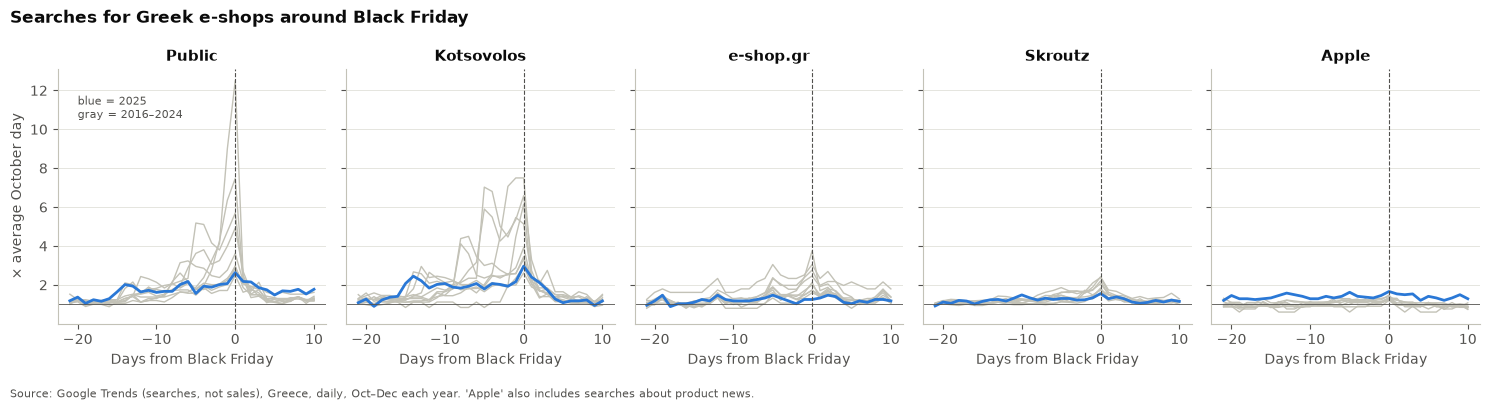

In [14]:
# [shops] One panel per shop: gray = 2016–2024, blue = 2025
win = shops[shops["days_from_bf"].between(-21, 10)]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8), sharey=True)
for ax, term in zip(axes, ORDER):
    t = win[win["term"] == term]
    for y, g in t.groupby("year"):
        if y != 2025:
            ax.plot(g["days_from_bf"], g["vs_october"], color=MUTED, lw=1)
    g = t[t["year"] == 2025]
    ax.plot(g["days_from_bf"], g["vs_october"], color=GREECE, lw=2)
    ax.axvline(0, color=INK2, lw=0.8, ls="--")
    ax.axhline(1, color=INK2, lw=0.6)
    ax.set_title(SHOP_NAMES[term], fontsize=11)
    ax.set_xlabel("Days from Black Friday")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("× average October day")
axes[0].text(-20, axes[0].get_ylim()[1] * 0.9, "blue = 2025\ngray = 2016–2024", fontsize=8, color=INK2, va="top")
fig.suptitle("Searches for Greek e-shops around Black Friday", x=0.01, ha="left", fontweight="bold", color=INK)
plt.figtext(0.01, -0.04, "Source: Google Trends (searches, not sales), Greece, daily, Oct–Dec each year. "
            "'Apple' also includes searches about product news.", fontsize=8, color=INK2)
plt.tight_layout()
fig.savefig(FIG / "03_eshop_searches_daily.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [15]:
# [shops] Black Friday day vs an average October day, per shop and year
bf_day = shops[shops["days_from_bf"] == 0].set_index(["term", "year"])["vs_october"]
spike = bf_day.unstack("year").loc[ORDER].round(1)
spike.index = [SHOP_NAMES[t] for t in ORDER]
spike.columns.name = "× Oct avg on Black Friday"

peak_on_bf = (shops.loc[shops.groupby(["term", "year"])["searches"].idxmax()]
              .assign(on_bf=lambda d: d["days_from_bf"] == 0)
              .groupby("term")["on_bf"].sum())
print("Years (of 10) where the shop's busiest search day was Black Friday:")
print(peak_on_bf.rename(SHOP_NAMES).loc[[SHOP_NAMES[t] for t in ORDER]].to_string())
spike

Years (of 10) where the shop's busiest search day was Black Friday:
term
Public        10
Kotsovolos     5
e-shop.gr      5
Skroutz        9
Apple          4


× Oct avg on Black Friday,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Public,12.5,7.5,5.7,4.9,3.6,3.0,2.9,2.9,2.5,2.6
Kotsovolos,6.1,7.5,5.1,6.6,3.9,3.5,2.9,3.3,2.6,3.0
e-shop.gr,2.1,3.7,2.5,2.8,3.0,1.7,2.0,1.6,1.7,1.2
Skroutz,1.8,2.2,2.1,2.4,2.4,1.8,1.5,1.7,1.6,1.6
Apple,1.2,1.3,1.3,1.5,1.3,1.2,1.3,1.4,1.3,1.7


**What 7b shows**
- **Public and Kotsovolos have the biggest Black Friday jumps.** On Black Friday their searches reach several times a normal October day. For Public, Black Friday was the busiest search day of October–December in all 10 years (2016–2025).
- **The spike is getting smaller.** Public went from about 12× a normal October day in 2016 to about 2.5× in 2024–2025; Kotsovolos from 6–7× to about 3×. Offers now run over a whole "Black Week" or most of November, so interest spreads over more days. For Kotsovolos and e-shop.gr the busiest day is now often a day or two before Black Friday (each peaked on the day itself in only 5 of 10 years).
- **Skroutz rises less but steadily:** about 1.5–2.5× on the day, and Black Friday was its busiest day in 9 of 10 years. As a price-comparison site it gets searches from people comparing offers across shops.
- **Apple barely moves** (about 1.2–1.7×). Its searches also follow product launches and news, so Black Friday was its peak in only 4 of 10 years.

**What 7b shows**
- **Public and Kotsovolos are the Black Friday shops.** On Black Friday their searches jump to several times a normal October day, and for Public the busiest day of the whole Oct–Dec period was Black Friday in every year from 2016 to 2025.
- **The spike is getting smaller.** Public went from about 12× a normal October day in 2016 to about 2.5× in 2024–2025; Kotsovolos from 6–7× to about 3×. Offers now run over a whole "Black Week" or most of November, so interest spreads over more days instead of one.
- **Skroutz and e-shop.gr rise less** (about 1.5–3×), and in recent years their busiest day is sometimes earlier in November.
- **Apple barely moves on Black Friday** (about 1.2–1.7×); its search peaks follow product launches and news instead.

## 8. Black Friday each year: searches vs November sales

The main chart. Top: how much Greece searched for Black Friday each November. Bottom: Greek retail sales volume in November compared with October. Two panels, not two axes on one chart, because the two measures have different scales.

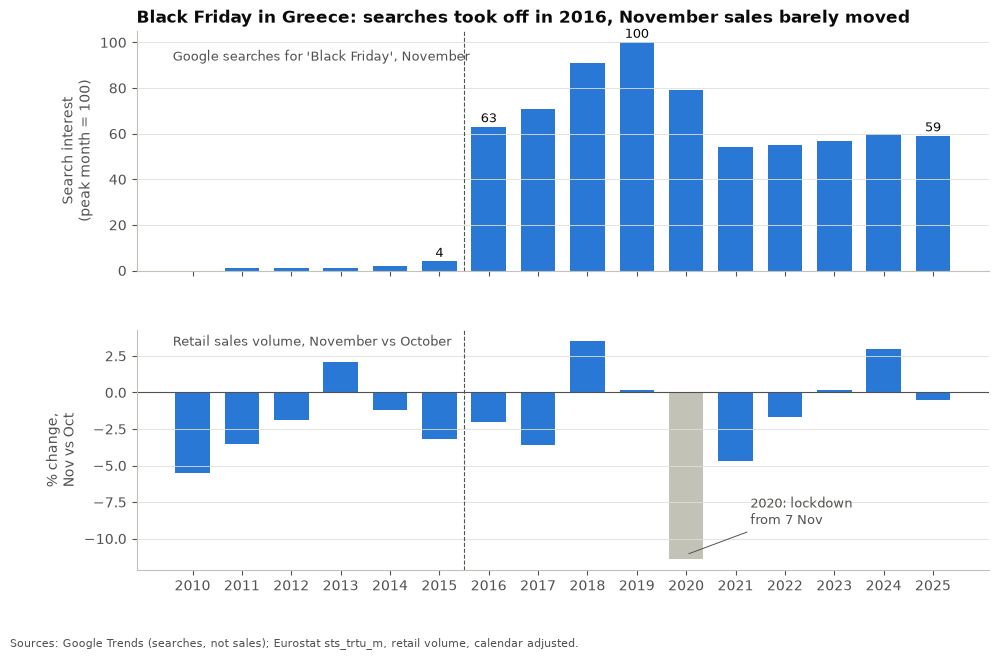

In [16]:
# [bf]
years = list(range(2010, 2026))
sales = bump.loc[years, "EL"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"hspace": 0.25})

ax1.bar(years, searches_nov.loc[years], color=GREECE, width=0.7)
ax1.set_ylabel("Search interest\n(peak month = 100)")
ax1.set_title("Black Friday in Greece: searches took off in 2016, November sales barely moved", loc="left")
for y in (2015, 2016, 2019, 2025):
    v = searches_nov.loc[y]
    ax1.text(y, v + 2, f"{v}", ha="center", fontsize=9, color=INK)
ax1.text(2009.6, 92, "Google searches for 'Black Friday', November", fontsize=9, color=INK2)

bar_colors = [MUTED if y == 2020 else GREECE for y in years]
ax2.bar(years, sales, color=bar_colors, width=0.7)
ax2.axhline(0, color=INK2, lw=0.8)
ax2.set_ylabel("% change,\nNov vs Oct")
ax2.text(2009.6, 3.2, "Retail sales volume, November vs October", fontsize=9, color=INK2)
ax2.annotate("2020: lockdown\nfrom 7 Nov", xy=(2020, sales.loc[2020] + 0.3), xytext=(2021.3, -9),
             fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.7))

for ax in (ax1, ax2):
    ax.axvline(2015.5, color=INK2, lw=0.8, ls="--")
    ax.grid(axis="x", visible=False)
ax2.set_xticks(years)
plt.figtext(0.01, 0.0, "Sources: Google Trends (searches, not sales); Eurostat sts_trtu_m, retail volume, calendar adjusted.",
            fontsize=8, color=INK2)
fig.savefig(FIG / "04_black_friday_searches_vs_sales.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [17]:
# [bf] The same numbers as a table
bf_table = pd.DataFrame({
    "Black Friday date": [black_friday(y).date() for y in years],
    "searches (Nov, 0–100)": searches_nov.loc[years].values,
    "sales Nov vs Oct (%)": sales.values,
}, index=pd.Index(years, name="year"))
bf_table

,Black Friday date,"searches (Nov, 0–100)",sales Nov vs Oct (%)
year,,,
2010,2010-11-26,0,-5.5
2011,2011-11-25,1,-3.5
2012,2012-11-23,1,-1.9
2013,2013-11-29,1,2.1
2014,2014-11-28,2,-1.2
2015,2015-11-27,4,-3.2
2016,2016-11-25,63,-2.0
2017,2017-11-24,71,-3.6
2018,2018-11-23,91,3.5


## 9. What Part 2 shows

- **Black Friday arrived in Greece in 2016.** Searches were near zero until 2015 (4 out of 100), then jumped to 63 in November 2016 and peaked in 2019. Since 2021 they have been steady at about 55–60.
- **Searches peak on Black Friday itself every year**, 2016–2025, so Greeks look for it on the day.
- **But November sales hardly changed.** Before 2016 Greek November sales were on average 2.2% below October; since 2016 (excluding 2020) 0.6% below. A big rise in interest, a small change in what was bought in the month.
- A likely reading: Black Friday **moves purchases within the season** (from early November or December into Black Friday week) more than it adds sales. The monthly data can't prove this; it only shows that the November total didn't grow much.


## 10. Did searches peak on Black Friday itself?

For each year, the day with the most "Black Friday" searches, compared with the actual Black Friday date.
<!-- renumbered -->

## 11. Black Friday each year: searches vs November sales

The main chart. Top: how much Greece searched for Black Friday each November. Bottom: Greek retail sales volume in November compared with October. Two panels, not two axes on one chart, because the two measures have different scales.
<!-- renumbered -->

## 12. What Part 2 shows

- **Black Friday arrived in Greece in 2016.** Searches were near zero until 2015 (4 out of 100), then jumped to 63 in November 2016 and peaked in 2019. Since 2021 they have been steady at about 55–60.
- **Searches peak on Black Friday itself every year**, 2016–2025, so Greeks look for it on the day.
- **But November sales hardly changed.** Before 2016 Greek November sales were on average 2.2% below October; since 2016 (excluding 2020) 0.6% below. A big rise in interest, a small change in what was bought in the month.
- A likely reading: Black Friday **moves purchases within the season** (from early November or December into Black Friday week) more than it adds sales. The monthly data can't prove this; it only shows that the November total didn't grow much.

<!-- renumbered -->

## 10. The November bump each year: Greece vs EU
<!-- renumbered -->

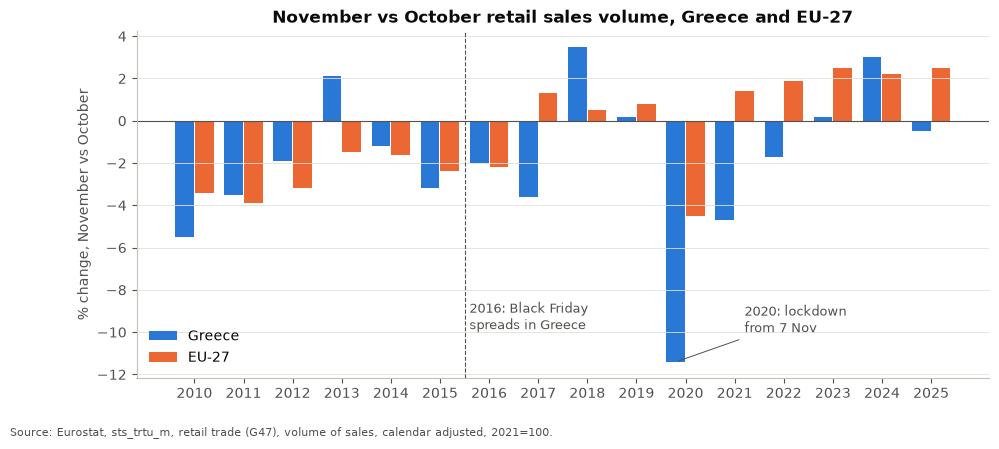

In [18]:
# [analysis]
fig, ax = plt.subplots(figsize=(11, 4.5))
years = bump.index
w = 0.38
ax.bar(years - w/2 - 0.01, bump["EL"], width=w, color=GREECE, label="Greece")
ax.bar(years + w/2 + 0.01, bump["EU27_2020"], width=w, color=EU, label="EU-27")
ax.axhline(0, color=INK2, lw=0.8)
ax.axvline(2015.5, color=INK2, lw=0.8, ls="--")
ax.text(2015.6, -8.5, "2016: Black Friday\nspreads in Greece", fontsize=9, color=INK2, va="top")
ax.annotate("2020: lockdown\nfrom 7 Nov", xy=(2020 - w/2, bump.loc[2020, "EL"]), xytext=(2021.2, -10),
            fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.7))
ax.set_xticks(years)
ax.set_ylabel("% change, November vs October")
ax.set_title("November vs October retail sales volume, Greece and EU-27")
ax.legend(frameon=False, loc="lower left")
ax.grid(axis="x", visible=False)
plt.figtext(0.01, -0.02, "Source: Eurostat, sts_trtu_m, retail trade (G47), volume of sales, calendar adjusted, 2021=100.",
            fontsize=8, color=INK2)
fig.savefig(FIG / "05_november_bump_greece_vs_eu.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 11. Before and after 2016
<!-- renumbered -->

In [19]:
# [analysis]
summary = pd.DataFrame({
    "2010–2015 avg": bump.loc[2010:2015, ["EL", "EU27_2020"]].mean(),
    "2016–2025 avg (excl. 2020)": bump.loc[YEARS_BF, ["EL", "EU27_2020"]].mean(),
    "2021–2025 avg": bump.loc[2021:2025, ["EL", "EU27_2020"]].mean(),
}).round(1)
summary["change (pp)"] = (summary["2016–2025 avg (excl. 2020)"] - summary["2010–2015 avg"]).round(1)
summary.index = ["Greece", "EU-27"]
summary

,2010–2015 avg,2016–2025 avg (excl. 2020),2021–2025 avg,change (pp)
Greece,-2.2,-0.6,-0.7,1.6
EU-27,-2.7,1.2,2.1,3.9


## 12. Ranking the EU countries by their November bump

Average November bump over **2021–2025** (the latest five years, all after the pandemic lockdowns). Only countries with all five years are ranked.
<!-- renumbered -->

Not ranked (missing years): ['SE']


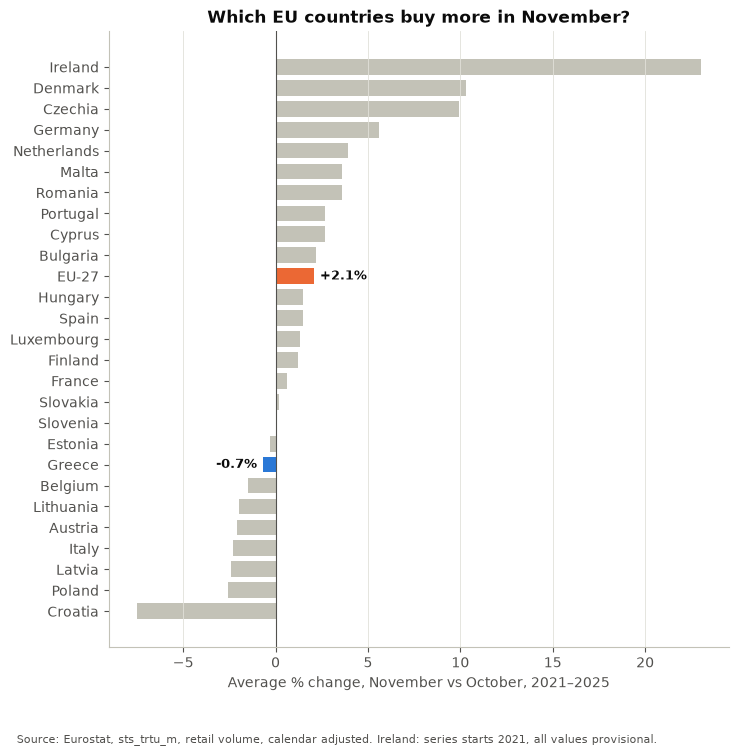

Greece ranks 19 of 26 countries.


In [20]:
# [analysis]
recent = bump.loc[2021:2025]
complete = recent.columns[recent.notna().sum() == 5]
print("Not ranked (missing years):", sorted(set(recent.columns) - set(complete)) or "none")

rank = recent[complete].mean().round(1).sort_values()
colors = [GREECE if g == "EL" else EU if g == "EU27_2020" else MUTED for g in rank.index]
names = df.drop_duplicates("geo").set_index("geo")["geo_name"]
labels = [("EU-27" if g == "EU27_2020" else names[g]) for g in rank.index]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(labels, rank.values, color=colors, height=0.75)
ax.axvline(0, color=INK2, lw=0.8)
for i, (g, v) in enumerate(rank.items()):
    if g in ("EL", "EU27_2020"):
        ax.text(v + (0.3 if v >= 0 else -0.3), i, f"{v:+.1f}%", va="center",
                ha="left" if v >= 0 else "right", fontsize=9, color=INK, fontweight="bold")
ax.set_xlabel("Average % change, November vs October, 2021–2025")
ax.set_title("Which EU countries buy more in November?")
ax.grid(axis="y", visible=False)
plt.figtext(0.01, -0.01, "Source: Eurostat, sts_trtu_m, retail volume, calendar adjusted. Ireland: series starts 2021, all values provisional.", fontsize=8, color=INK2)
fig.savefig(FIG / "06_eu_ranking_november_bump.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

greece_pos = list(rank.sort_values(ascending=False).drop("EU27_2020").index).index("EL") + 1
print(f"Greece ranks {greece_pos} of {len(rank) - 1} countries.")

## 13. Which month do Greeks shop most?

Each month as a % of that year's monthly average (100 = an average month), averaged over 2021–2025. This shows the whole year's shape, not just November.
<!-- renumbered -->

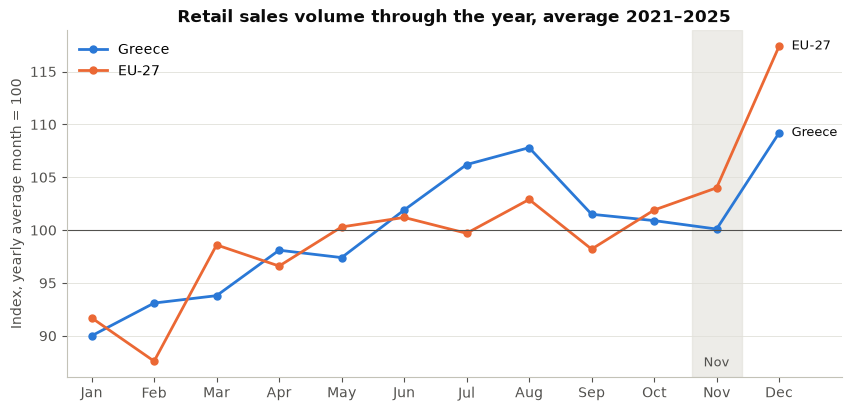

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
geo,,,,,,,,,,,,
EL,90.0,93.1,93.8,98.1,97.4,101.9,106.2,107.8,101.5,100.9,100.1,109.2
EU27_2020,91.7,87.6,98.6,96.6,100.3,101.2,99.7,102.9,98.2,101.9,104.0,117.4


In [21]:
# [analysis]
prof = vol_ca.loc["2021":"2025", ["EL", "EU27_2020"]]
prof = prof.groupby(prof.index.year).transform(lambda s: s / s.mean() * 100)
profile = prof.groupby(prof.index.month).mean().round(1)
profile.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(12)
ax.plot(x, profile["EL"], color=GREECE, lw=2, marker="o", ms=5, label="Greece")
ax.plot(x, profile["EU27_2020"], color=EU, lw=2, marker="o", ms=5, label="EU-27")
ax.axhline(100, color=INK2, lw=0.8)
ax.axvspan(9.6, 10.4, color=GRID, alpha=0.6, zorder=0)
ax.text(10, ax.get_ylim()[0] + 1, "Nov", ha="center", fontsize=9, color=INK2)
for col, name, c in [("EL", "Greece", GREECE), ("EU27_2020", "EU-27", EU)]:
    ax.text(11.2, profile[col].iloc[-1], name, color=INK, fontsize=9, va="center")
ax.set_xticks(list(x), profile.index)
ax.set_xlim(-0.4, 12)
ax.set_ylabel("Index, yearly average month = 100")
ax.set_title("Retail sales volume through the year, average 2021–2025")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "07_monthly_profile_greece_vs_eu.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

profile.T

## 14. What this shows

*(Numbers from the cells above, Eurostat data as of 25 Nov 2026.)*

- **Greece has almost no November bump.** In the Black Friday era (2016–2025, excl. 2020), Greek retail volume in November averaged **slightly below October**, while the EU average turned positive.
- **The EU changed more than Greece did.** Before 2016 both had a November dip. Since then the EU-27 moved to about **+2%** a year, while Greece improved only by about 1.6 points and is still around zero.
- **Greece ranks in the bottom third of the EU.** Greece ranks **19th of 26** (Sweden is not ranked: too few years). Denmark, Czechia and Germany have big November jumps; Greece sits with Italy, Austria, Poland and Croatia near or below zero.
- **Greece's peak month is summer, not November.** Tourism lifts July and August above average, and December is Greece's only real shopping peak (about +9% over an average month vs about +17% for the EU). November is just an average month in Greece; across the EU it is already above average.

**Caveats for the post**
- October in Greece is still partly tourist season, which raises October and makes the Nov/Oct jump look smaller. The month profile (section 10) avoids this and shows the same result.
- These are whole-month figures for all retail. They show that November does or doesn't rise; they can't isolate Black Friday weekend itself.
- 2020 is left out of averages (Greek lockdown from 7 Nov 2020).
- **Ireland (+23%) is an outlier**: its series only starts in 2021, every value is provisional, and its December is about 60% above an average month. Mention it with that caution, or leave it out of the headline.
- Croatia sits last for the same tourism reason as Greece, only stronger: a high October, not a weak November.
- Several countries' figures are provisional (`p` flag) and may be revised by a few tenths.
<!-- renumbered -->